# Notebook 07 - diagnosis: which relationships changed?
We compare **TreeSHAP** feature attributions for a model trained on 2022-2025 against one that also sees 2026, both explained on the 2026 laps. Features whose importance moves are the relationships the regulation change altered. Reads `data/model_table.csv.gz` and `results/xgb_params.json`.

In [1]:
import os, sys
# Run from the repo root so data/, figures/ and results/ resolve, and make src/ importable.
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
sys.path.insert(0, os.path.abspath('src'))

import json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import xgboost as xgb
from f1lap.features import encode_features
from f1lap.models import SEED, PARAMS_PATH, make_xgb

np.random.seed(SEED)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
df = pd.read_csv('data/model_table.csv.gz')
X_all = encode_features(df)          # one aligned matrix, sliced per split
y_all = df['lap_delta_s']
FEATURE_COLS = list(X_all.columns)

XGB_PARAMS = json.load(open(PARAMS_PATH))

### 1. SHAP before vs after seeing 2026
SHAP values come straight from **XGBoost's native `pred_contribs`**, which is the same TreeSHAP algorithm the `shap` library wraps, so there's no extra dependency.

In [2]:
m_pre = make_xgb(**XGB_PARAMS).fit(X_all[df.season < 2026], y_all[df.season < 2026].values)
m_post = make_xgb(**XGB_PARAMS).fit(X_all, y_all.values)
dm = xgb.DMatrix(X_all[df.season == 2026])
def mean_abs_shap(m):
    c = m.get_booster().predict(dm, pred_contribs=True)[:, :-1]   # drop the bias column
    return pd.Series(np.abs(c).mean(0), index=FEATURE_COLS)
shap_cmp = pd.DataFrame({'2022-2025': mean_abs_shap(m_pre), 'incl_2026': mean_abs_shap(m_post)})
shap_cmp['change'] = shap_cmp['incl_2026'] - shap_cmp['2022-2025']
top = shap_cmp.sort_values('incl_2026', ascending=False).head(12)
print('Mean |SHAP| on 2026 laps (top 12 features):')
top.round(4)

Mean |SHAP| on 2026 laps (top 12 features):


,2022-2025,incl_2026,change
position,0.4832,0.5854,0.1022
fuel_proxy,0.5827,0.5382,-0.0444
stint,0.2296,0.2347,0.0050
tyre_age,0.1875,0.1586,-0.0289
team_Cadillac,0.0000,0.0869,0.0869
air_temp_c,0.0874,0.0726,-0.0148
track_temp_c,0.0537,0.0597,0.0060
team_Red Bull Racing,0.0297,0.0324,0.0027
team_Ferrari,0.0221,0.0283,0.0062
team_Mercedes,0.0214,0.0275,0.0061


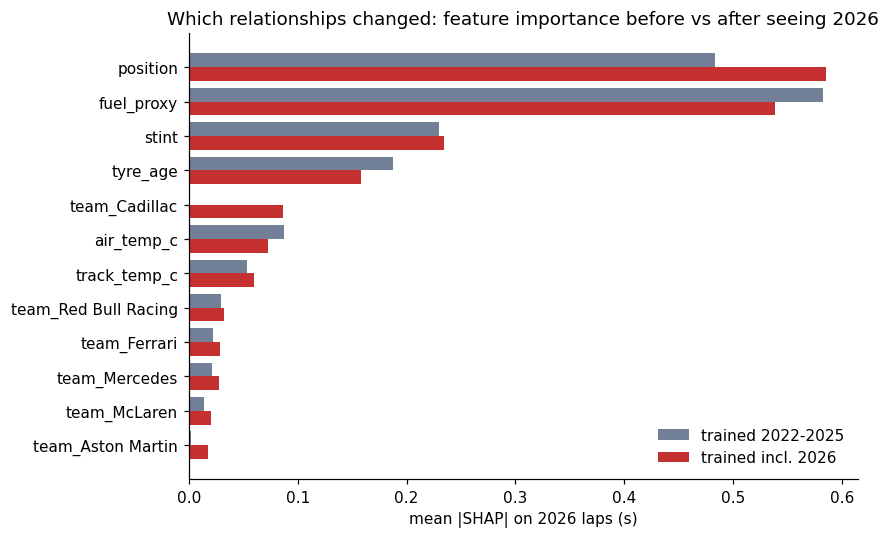

In [3]:
t = top.sort_values('incl_2026')
yy = np.arange(len(t)); h = 0.4
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(yy + h / 2, t['2022-2025'], height=h, label='trained 2022-2025', color='#718096')
ax.barh(yy - h / 2, t['incl_2026'], height=h, label='trained incl. 2026', color='#c53030')
ax.set_yticks(yy); ax.set_yticklabels(t.index); ax.set_xlabel('mean |SHAP| on 2026 laps (s)')
ax.set_title('Which relationships changed: feature importance before vs after seeing 2026')
ax.legend(frameon=False)
plt.tight_layout(); plt.savefig('figures/08_shap_comparison.png', dpi=150); plt.show()

**Figure 08.** Once 2026 is in training, the model leans **more on `position`** (the biggest rise of any existing feature) and picks up **`team_Cadillac`** from zero, while `fuel_proxy` and `tyre_age` importance slightly fall. Be careful reading `position`: it isn't really "where you run in the field matters more". Running position is mostly a stand-in for car pace (fast cars run at the front), so its rise most likely means the 2026 pecking order reshuffled and the model is using position to recover pace information that the team columns can no longer provide. Note also that the "incl. 2026" model is explained on laps it was trained on, so this is an attribution comparison, not a test score.